# Assignment Instructions - Part 1: Exploritory Data Analysis

Statistics are the simplest data-driven components of a model. They summarize observations, quantify variation, and show what a sample can and cannot support. In this activity you will get real data from a **web API**, check it, and ask what statistics alone can tell you before any machine learning is added.

The data are 75 years of daily weather for one location from the Open-Meteo historical archive. Weather matters across ecology, agriculture, energy, health, and engineering, and its messiness (seasons, trends, grid cells, units) is typical of real research data.

## Learning goals

By the end of this activity, you should be able to:

- explain what a web API is and request data from one with Python;
- compare an open API with one that needs a key, and handle keys safely;
- record where a dataset came from so a teammate can repeat the download; and
- summarize a time series with means, confidence intervals, and a trend, and explain what those statistics cannot claim.


## 1. Finding a dataset

Before analyzing any dataset, decide whether it fits your question. Several weather sources are common:
| Source | Type | Access | Good for |
|---|---|---|---|
| [Open-Meteo](https://open-meteo.com/en/docs/historical-weather-api) | Reanalysis (ERA5) on a grid, any lat/lon | No account or key | Quick, reproducible downloads |
| [NOAA GHCN-Daily](https://www.ncei.noaa.gov/products/land-based-station/global-historical-climatology-network-daily) | Real station observations | Free; files or token | Citing observed station records |
| [Meteostat](https://meteostat.net/) | Station data with a Python package | Free | Station data with little code |
| [NASA POWER](https://power.larc.nasa.gov/) | Satellite and model data | Free | Solar and agro-climate variables |

We will use Open-Meteo. Its historical values come from the ERA5 *reanalysis*, which blends observations with a physical model on a regular grid, so the numbers describe a grid cell near your point rather than a thermometer at a specific station.

### Your turn: read the documentation

Open the [Open-Meteo historical weather documentation](https://open-meteo.com/en/docs/historical-weather-api) and the [license page](https://open-meteo.com/en/license). 

## 2. What is a web API?

You already use *package* APIs: `import scipy` gives you functions that run inside your own Python process. A **web API** works differently. Your program sends a request over the internet to a URL (Uniform Resource Identifier), a server runs the work somewhere else, and it sends back a response. You do not install the provider's code, and you do not control it. It can change, slow down, limit you, or disappear.

A request is just a URL with a few parts:

```
https://archive-api.open-meteo.com/v1/archive?latitude=42.73&longitude=-84.48&daily=temperature_2m_mean
\___________________________________________/ \_______________________________________________________/
              endpoint                                    parameters (after the ?, joined by &)
```

The response has a **status code** (200 means success, 4xx means your request was wrong, 5xx means the server failed) and a **body**, which here is JSON. You can paste the URL above into a browser and see the same thing Python will receive.

The `requests` package builds the URL from a dictionary of parameters and sends it.

In [1]:
import hashlib
import json
import os
import sys
from datetime import date
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
from scipy import stats

print(f'Python: {sys.version.split()[0]}, requests: {requests.__version__}')

API_URL = 'https://archive-api.open-meteo.com/v1/archive'

# A tiny request: three days at one location.
small_query = {
    'latitude': 42.73,
    'longitude': -84.48,
    'start_date': '2024-01-01',
    'end_date': '2024-01-03',
    'daily': 'temperature_2m_mean',
}

response = requests.get(API_URL, params=small_query, timeout=60)
print('Status code:', response.status_code)
print('URL sent:   ', response.url)
print(json.dumps(response.json(), indent=2))

Python: 3.12.9, requests: 2.32.3
Status code: 200
URL sent:    https://archive-api.open-meteo.com/v1/archive?latitude=42.73&longitude=-84.48&start_date=2024-01-01&end_date=2024-01-03&daily=temperature_2m_mean
{
  "latitude": 42.7065,
  "longitude": -84.416534,
  "generationtime_ms": 0.5263090133666992,
  "utc_offset_seconds": 0,
  "timezone": "GMT",
  "timezone_abbreviation": "GMT",
  "elevation": 259.0,
  "daily_units": {
    "time": "iso8601",
    "temperature_2m_mean": "\u00b0C"
  },
  "daily": {
    "time": [
      "2024-01-01",
      "2024-01-02",
      "2024-01-03"
    ],
    "temperature_2m_mean": [
      -1.1,
      -1.0,
      0.5
    ]
  }
}


### Your turn: read the response and break the request

1. Find the temperature values in the JSON. Which keys hold them, and what are their units?
2. Compare the `latitude` and `longitude` in the response with what you asked for. What does that tell you about gridded data?
3. Make the request fail on purpose by changing `bad_query` below (try a latitude of 200, a misspelled parameter, or an end date before the start date). Run it and read the status code and the message. Then fix it.

In [2]:
bad_query = {**small_query, 'latitude': 200}  # Your turn: change this

bad = requests.get(API_URL, params=bad_query, timeout=60)
print(bad.status_code)
print(bad.json())

400
{'error': True, 'reason': 'Latitude must be in range of -90 to 90°. Given: 200.0.'}


## 3. Open web APIs versus web APIs that need a key

Open-Meteo asks for nothing: no account, no key. Many providers want to know who is calling, to enforce limits or charge for use. They issue an **API key** (or *token*), a secret string that you send with every request, usually in a header. NOAA Climate Data Online works this way. You request a free token by email and send it in a header named `token`.

The cell below calls a NOAA endpoint **without** a token. Run it and notice what the server says. Nothing in the request is wrong except the missing key.

In [3]:
NOAA_URL = 'https://www.ncei.noaa.gov/cdo-web/api/v2/datasets'

try:
    no_key = requests.get(NOAA_URL, params={'limit': 1}, timeout=30)
    print(no_key.status_code)
    print(no_key.text[:300])
except requests.RequestException as err:
    print(f'Request failed ({type(err).__name__}): an unreachable service is a failure mode too.')

400
{"status" : "400", "message" : "Token parameter is required."}


Treat a key like a password. Never type it into a notebook cell or commit it to Git, because notebooks and their history get shared. Read it from an **environment variable** instead. Set the variable outside the notebook (in your shell, or in a git-ignored `.env` file), and your code only ever names it:

```python
token = os.environ['NOAA_CDO_TOKEN']                  # fails loudly if it is missing
requests.get(NOAA_URL, headers={'token': token}, params={'limit': 1})
```

If a key is ever exposed, revoke it and request a new one.

### Your turn: a safe key loader

The `get_token` function below reads an environment variable, but it fails silently when the variable is missing, so a request would go out with no key and a confusing error would come back later. Improve it so it raises an error that names the missing variable (but never prints a key). Then rerun the test cell.

In [4]:
def get_token(variable_name):
    '''Return the API key stored in an environment variable.'''
    # Your turn: raise a helpful error if the variable is missing
    return os.environ.get(variable_name)


os.environ['DEMO_TOKEN'] = 'not-a-real-key'  # for this test only; real keys are set outside the notebook
assert get_token('DEMO_TOKEN') == 'not-a-real-key'
try:
    result = get_token('SURELY_NOT_SET')
    print(f'No error raised; get_token returned {result!r}. Is that safe?')
except (KeyError, RuntimeError, ValueError) as err:
    print('Missing variable reported:', err)

No error raised; get_token returned None. Is that safe?


### Discuss

- What does the status code tell you when a key is missing, compared with a malformed request?
- If the provider renames a parameter next year, what happens to your analysis? How is that different from a package pinned in `environment.yml`?
- Why is a key in an environment variable safer than one typed into a cell?

**Your answers:**

*(double-click to edit)*

## 4. Download the full dataset and record where it came from

Now request the whole record: 75 full calendar years, so no season is over-represented at the start or end. Settings that define a dataset belong in one place so a teammate can repeat your work.

The function below saves the response to a file and downloads only if that file is missing, so rerunning the notebook does not repeat the request. The file name comes from the query, so a new location never silently reuses an old file. Next to the data it saves the full URL, the access date, and a SHA-256 checksum. Those three items are the provenance a teammate would need.

In [5]:
DATA_DIR = Path('data')
LOCATION_NAME = 'East Lansing, MI'
QUERY = {
    'latitude': 42.73,
    'longitude': -84.48,
    'start_date': '1950-01-01',
    'end_date': '2024-12-31',
    'daily': 'temperature_2m_mean,precipitation_sum',
    'timezone': 'America/Detroit',
}


def download_weather(query, data_dir=DATA_DIR, refresh=False):
    '''Download an Open-Meteo archive query, caching the JSON and its provenance.'''
    data_dir.mkdir(exist_ok=True)
    query_id = hashlib.sha256(json.dumps(query, sort_keys=True).encode()).hexdigest()[:8]
    data_path = data_dir / f'open_meteo_{query_id}.json'
    meta_path = data_path.with_suffix('.meta.json')

    if refresh or not data_path.exists():
        response = requests.get(API_URL, params=query, timeout=60)
        response.raise_for_status()
        data_path.write_bytes(response.content)
        metadata = {
            'url': response.url,
            'accessed': date.today().isoformat(),
            'sha256': hashlib.sha256(response.content).hexdigest(),
        }
        meta_path.write_text(json.dumps(metadata, indent=2))

    return json.loads(data_path.read_text()), json.loads(meta_path.read_text())


payload, provenance = download_weather(QUERY)
print(json.dumps(provenance, indent=2))

{
  "url": "https://archive-api.open-meteo.com/v1/archive?latitude=42.73&longitude=-84.48&start_date=1950-01-01&end_date=2024-12-31&daily=temperature_2m_mean%2Cprecipitation_sum&timezone=America%2FDetroit",
  "accessed": "2026-10-29",
  "sha256": "235563362d8b1492379e67841814a0533356c4554fe7b11b298fc60e5e44945b"
}


Statistics computed on unchecked data can be precisely wrong, so convert the response to a table indexed by date and check it before analyzing anything. Passing these checks does not prove the data are correct, but failing them tells you to stop.

### Your turn: define "plausible"

Change `TEMP_BOUNDS` to the range of daily mean temperature you think is physically reasonable for this location, then run the cell.

In [6]:
weather = pd.DataFrame(payload['daily']).rename(
    columns={'temperature_2m_mean': 'temp_c', 'precipitation_sum': 'precip_mm'}
)
weather['time'] = pd.to_datetime(weather['time'])
weather = weather.set_index('time')

assert payload['daily_units']['temperature_2m_mean'] == '°C'
assert payload['daily_units']['precipitation_sum'] == 'mm'

expected_days = pd.date_range(QUERY['start_date'], QUERY['end_date'], freq='D')
print(f'Rows: {len(weather)} (expected {len(expected_days)})')
print(f'Complete daily index: {weather.index.equals(expected_days)}')
print(f'Missing values:\n{weather.isna().sum()}')

Rows: 27394 (expected 27394)
Complete daily index: True
Missing values:
temp_c       0
precip_mm    0
dtype: int64


Days outside (-60, 60): 0
Days with negative precipitation: 0


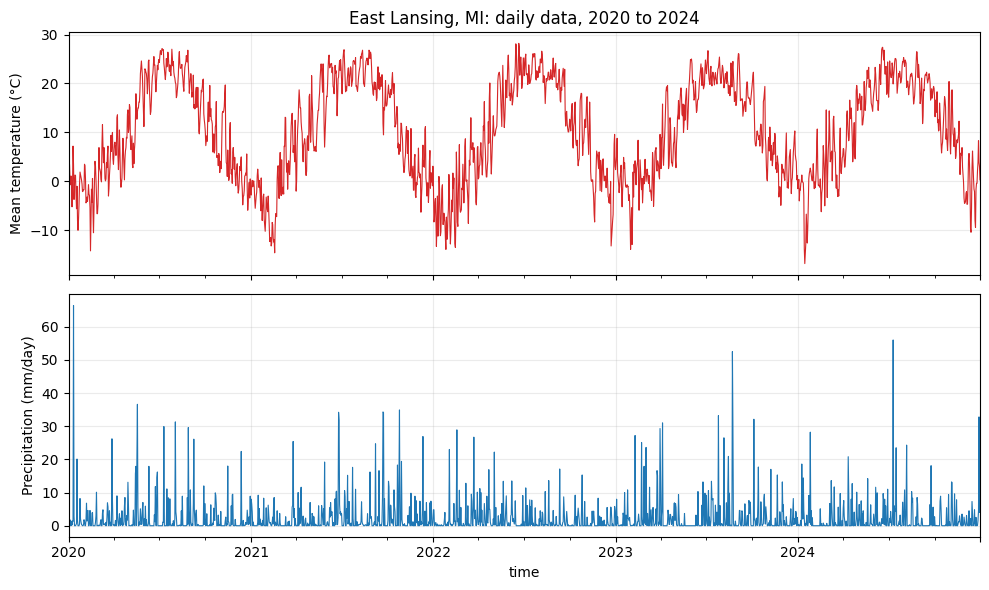

In [7]:
TEMP_BOUNDS = (-60, 60)  # Your turn: choose bounds you can defend
PLOT_YEARS = ('2020', '2024')  # Your turn: try a different stretch

outside = weather[(weather['temp_c'] < TEMP_BOUNDS[0]) | (weather['temp_c'] > TEMP_BOUNDS[1])]
print(f'Days outside {TEMP_BOUNDS}: {len(outside)}')
print(f'Days with negative precipitation: {(weather["precip_mm"] < 0).sum()}')

fig, axes = plt.subplots(2, 1, figsize=(10, 6), sharex=True)
weather.loc[PLOT_YEARS[0]:PLOT_YEARS[1], 'temp_c'].plot(ax=axes[0], color='tab:red', linewidth=0.8)
axes[0].set_ylabel('Mean temperature (°C)')
weather.loc[PLOT_YEARS[0]:PLOT_YEARS[1], 'precip_mm'].plot(ax=axes[1], color='tab:blue', linewidth=0.8)
axes[1].set_ylabel('Precipitation (mm/day)')
axes[0].set_title(f'{LOCATION_NAME}: daily data, {PLOT_YEARS[0]} to {PLOT_YEARS[1]}')
for ax in axes:
    ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()

## 5. Descriptive statistics and the seasonal cycle

The mean estimates a typical value and the standard deviation describes spread. For a time series, ask what the spread is measuring. The overall spread of daily temperature is dominated by the seasons, so it says little about how unusual one day is. Grouping by calendar month separates the seasonal signal from day-to-day variation.

count    27394.00
mean         9.08
std         10.90


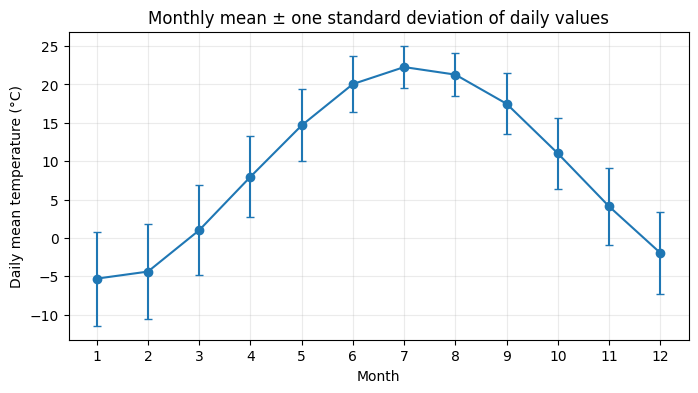

In [8]:
print(weather['temp_c'].agg(['count', 'mean', 'std']).round(2).to_string())

monthly = weather.groupby(weather.index.month)['temp_c'].agg(['mean', 'std'])
monthly.index.name = 'month'

plt.figure(figsize=(8, 4))
plt.errorbar(monthly.index, monthly['mean'], yerr=monthly['std'], fmt='o-', capsize=3)
plt.xticks(range(1, 13))
plt.xlabel('Month')
plt.ylabel('Daily mean temperature (°C)')
plt.title('Monthly mean ± one standard deviation of daily values')
plt.grid(alpha=0.25)
plt.show()

### Your turn: summarize precipitation

Repeat the monthly summary for `precip_mm`: group by month, take the mean and standard deviation, and make a bar chart of the monthly mean. Then answer the questions below.

In [9]:
# Your code here


- How does the spread within one month compare with the overall spread of temperature? What does that say about how much variation is seasonal?
- Is the mean a good summary of daily precipitation? Compare the standard deviation with the mean.
- What information is lost when you report one overall mean?

**Your answers:**

*(double-click to edit)*

## 6. Uncertainty and sample size

A confidence interval summarizes uncertainty in an estimate of a mean under a set of assumptions. It is not a range containing most individual values.

There is a catch for time series. A warm day is usually followed by another warm day, so about 27,000 daily values are nowhere near 27,000 independent pieces of evidence, and an interval built from them would badly understate the uncertainty. Annual means are much closer to independent, so we work with one value per year: about 75 observations instead of 27,000.

In [10]:
def mean_confidence_interval(values, confidence=0.95):
    '''Return the mean and a t-based confidence interval for numeric values.'''
    values = np.asarray(values, dtype=float)
    if values.size < 2:
        raise ValueError('At least two observations are required.')

    mean = values.mean()
    standard_error = stats.sem(values)
    interval = stats.t.interval(confidence, df=values.size - 1, loc=mean, scale=standard_error)
    return mean, interval


annual_temp = weather['temp_c'].groupby(weather.index.year).mean()
annual_temp.index.name = 'year'

mean_all, ci_all = mean_confidence_interval(annual_temp)
print(f'Mean annual temperature: {mean_all:.2f} °C')
print(f'95% confidence interval: ({ci_all[0]:.2f}, {ci_all[1]:.2f})')

Mean annual temperature: 9.08 °C
95% confidence interval: (8.89, 9.28)


### Your turn: how many years do we need?

The cell below computes the interval from only the most recent `n` years. Predict how the interval width changes as `n` grows, then edit `SAMPLE_YEARS` and check. Notice whether the *mean* also changes.

In [11]:
SAMPLE_YEARS = [5, 10, 20, 40, len(annual_temp)]  # Your turn: try other sizes

rows = []
for n_years in SAMPLE_YEARS:
    mean, (low, high) = mean_confidence_interval(annual_temp.iloc[-n_years:])
    rows.append({'years_used': n_years, 'mean': mean, 'lower': low, 'upper': high, 'width': high - low})

pd.DataFrame(rows).round(2)

,years_used,mean,lower,upper,width
0,5,10.28,9.56,11.00,1.45
1,10,9.94,9.45,10.43,0.98
2,20,9.68,9.27,10.09,0.81
3,40,9.44,9.17,9.72,0.55
4,75,9.08,8.89,9.28,0.38


Larger samples reduce random uncertainty but cannot fix bias or a changing baseline. Which of those two problems might this record have? **Your answer:**

*(double-click to edit)*

## 7. Trends over time

A trend is the simplest data-driven model of a time series: a straight line through the annual means. The slope estimates how fast the average is changing, and its standard error gives a confidence interval. We report slope per decade because it is easier to interpret.

### Your turn

Run the cell, then change `TREND_START` to 1990 and rerun. How do the slope and the width of its interval change?

Trend: 0.178 °C per decade
95% confidence interval: (0.099, 0.257) °C per decade
Lag-1 autocorrelation of residuals: 0.16


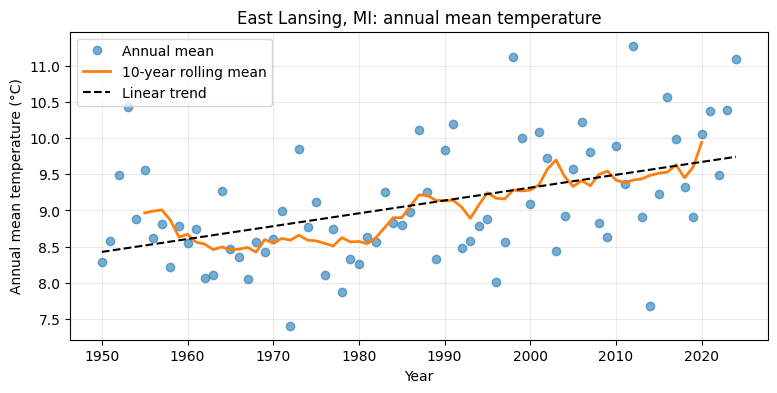

In [12]:
TREND_START = 1950  # Your turn: try 1990

trend_data = annual_temp.loc[TREND_START:]
years = trend_data.index.to_numpy()
fit = stats.linregress(years, trend_data.to_numpy())

margin = stats.t.ppf(0.975, df=len(years) - 2) * fit.stderr * 10
print(f'Trend: {fit.slope * 10:.3f} °C per decade')
print(f'95% confidence interval: ({fit.slope * 10 - margin:.3f}, {fit.slope * 10 + margin:.3f}) °C per decade')

residuals = trend_data.to_numpy() - (fit.intercept + fit.slope * years)
print(f'Lag-1 autocorrelation of residuals: {np.corrcoef(residuals[:-1], residuals[1:])[0, 1]:.2f}')

plt.figure(figsize=(9, 4))
plt.plot(years, trend_data, 'o', alpha=0.6, label='Annual mean')
plt.plot(years, trend_data.rolling(10, center=True).mean(), color='tab:orange', linewidth=2, label='10-year rolling mean')
plt.plot(years, fit.intercept + fit.slope * years, 'k--', label='Linear trend')
plt.xlabel('Year')
plt.ylabel('Annual mean temperature (°C)')
plt.title(f'{LOCATION_NAME}: annual mean temperature')
plt.legend()
plt.grid(alpha=0.25)
plt.show()

The interval assumes the residuals (departures from the line) are independent. A lag-1 autocorrelation near zero supports that; a large positive value means the real uncertainty is larger than the interval suggests.

- Is the trend distinguishable from zero? Is it large enough to matter for a question you care about?
- Why does a shorter record give a wider interval?
- A line is one model choice. What does the rolling mean show that the line cannot?

**Your answers:**

*(double-click to edit)*

### Your turn: does the trend depend on the season?

The annual trend averages over every month. Write a function `monthly_trend(month)` that selects the daily rows for one calendar month, averages them by year, fits `stats.linregress`, and returns the slope per decade. Compare January with July.

In [13]:
# Your code here


**What did the annual trend hide? Your answer:**

*(double-click to edit)*

## 8. Association is not explanation

Pearson correlation describes the strength of a *linear* association. Compare annual mean temperature with annual total precipitation, one point per year.

Pearson correlation: -0.013 (p = 0.909)


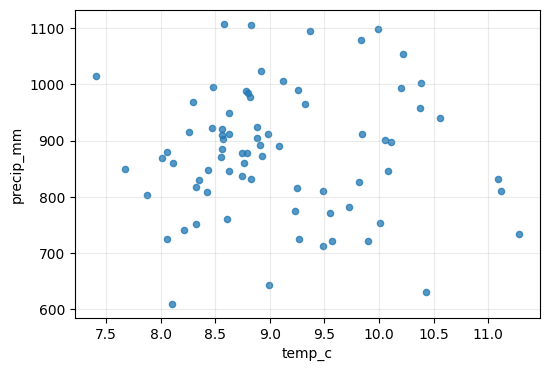

In [14]:
annual = pd.DataFrame(
    {
        'temp_c': annual_temp,
        'precip_mm': weather['precip_mm'].groupby(weather.index.year).sum(),
    }
)

r, p_value = stats.pearsonr(annual['temp_c'], annual['precip_mm'])
print(f'Pearson correlation: {r:.3f} (p = {p_value:.3g})')

annual.plot.scatter('temp_c', 'precip_mm', alpha=0.75, figsize=(6, 4))
plt.grid(alpha=0.25)
plt.show()

### Your turn

Two series that each drift over time can look correlated only because both depend on the calendar. Correlate the *year-to-year changes* (`annual.diff().dropna()`) instead of the levels. Does the conclusion change? What can and cannot be concluded from either correlation?

In [15]:
# Your code here


**Your answer:**

*(double-click to edit)*

## 9. Make it yours

Choose **at least one** and complete it with code and short notes:

1. Change `LOCATION_NAME` and the coordinates in `QUERY` to a place that matters to you, then rerun from section 4. How does the trend compare?
2. Change `daily` to `temperature_2m_max` or `temperature_2m_min` (and the column rename). Does the trend differ from the mean temperature?
3. Find a different public dataset or API from your own field. Record its `source_notes` and note whether it needs a key.

Record the location, dates, variables, and the provenance from section 4, because those settings are part of a reproducible experiment.

## Reflection

In a short response, address all four prompts:

- What did the summaries and the trend reveal, and what did they not reveal?
- Which assumption (independence, a stable baseline, a straight-line trend, reanalysis equals reality) most limits your conclusions?
- What would a teammate need, beyond this notebook, to repeat your download and analysis? Which parts depend on a web API you do not control?
- In your own research, which data source might you use, and what would you check before trusting it?

**Your reflection:**

*(double-click to edit)*

## Before the next class

Keep this notebook and your notes. The next activity moves from description toward prediction and asks when machine learning is genuinely warranted. Think about whether this dataset could support a prediction task, and whether you would have enough independent observations to try.